Task 1 - Bluegills Polynomial Regression

Original Dataset Head:
    age  length
0    1      67
1    1      62
2    2     109
3    2      83
4    2      91 

Degree 1 | Train RMSE: 11.78 | Test RMSE: 14.45 | R²: 0.7206
Degree 2 | Train RMSE: 10.35 | Test RMSE: 12.03 | R²: 0.8063
Degree 3 | Train RMSE: 10.34 | Test RMSE: 12.09 | R²: 0.8044
Degree 4 | Train RMSE: 10.33 | Test RMSE: 12.26 | R²: 0.7989
Degree 5 | Train RMSE: 10.24 | Test RMSE: 12.37 | R²: 0.7951


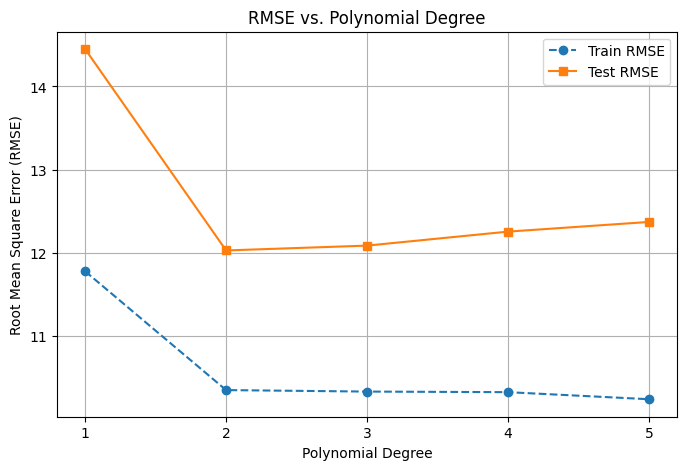


Best Polynomial Degree based on Test RMSE: 2

Predicted length for age 5 (using degree 2): 167.42
Actual lengths for age 5 in dataset: [171 188 170 150 150 160 160 180]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('bluegills.txt', sep='\t')
print("Original Dataset Head:\n", df.head(), "\n")

X = df[['age']].values
y = df['length'].values

scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

train_rmse_list = []
test_rmse_list = []
r2_list = []
degrees = range(1, 6)

best_degree = 1
lowest_test_rmse = float('inf')
best_model = None
best_poly_features = None

for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    r2 = r2_score(y_test, y_test_pred)

    train_rmse_list.append(train_rmse)
    test_rmse_list.append(test_rmse)
r2_list.append(r2)

print(f"Degree {d} | Train RMSE: {train_rmse:.2f} | Test RMSE: {test_rmse:.2f} | R²: {r2:.4f}")

if test_rmse < lowest_test_rmse:
        lowest_test_rmse = test_rmse
        best_degree = d
        best_model = model
        best_poly_features = poly

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rmse_list, label='Train RMSE', marker='o', linestyle='--')
plt.plot(degrees, test_rmse_list, label='Test RMSE', marker='s', linestyle='-')
plt.title('RMSE vs. Polynomial Degree')
plt.xlabel('Polynomial Degree')
plt.ylabel('Root Mean Square Error (RMSE)')
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

print(f"\nBest Polynomial Degree based on Test RMSE: {best_degree}")

age_to_predict = np.array([[5]])
age_scaled = scaler_X.transform(age_to_predict)
age_poly = best_poly_features.transform(age_scaled)
predicted_length = best_model.predict(age_poly)[0]

print(f"\nPredicted length for age 5 (using degree {best_degree}): {predicted_length:.2f}")

actual_lengths = df[df['age'] == 5]['length'].values
print(f"Actual lengths for age 5 in dataset: {actual_lengths}")

Task 2 - Nifty Energy Polynomial Regression

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df_nifty = pd.read_csv('NIFTY ENERGY.csv')

df_nifty = df_nifty.dropna()

X_nifty = np.arange(len(df_nifty)).reshape(-1, 1)
y_nifty = df_nifty['Close'].values

scaler_nifty = StandardScaler()
X_nifty_scaled = scaler_nifty.fit_transform(X_nifty)

print("--- NIFTY ENERGY Regression Models ---")

for d in range(1, 6):
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X_nifty_scaled)

    model = LinearRegression()
    model.fit(X_poly, y_nifty)

    y_pred = model.predict(X_poly)
    r2 = r2_score(y_nifty, y_pred)

    model_name = "Linear Regression (Deg 1)" if d == 1 else f"Polynomial Regression (Deg {d})"
    print(f"{model_name:30} | R² Score: {r2:.4f}")

--- NIFTY ENERGY Regression Models ---
Linear Regression (Deg 1)      | R² Score: 0.9041
Polynomial Regression (Deg 2)  | R² Score: 0.9416
Polynomial Regression (Deg 3)  | R² Score: 0.9443
Polynomial Regression (Deg 4)  | R² Score: 0.9712
Polynomial Regression (Deg 5)  | R² Score: 0.9755
